# Clustering

Hierarchical clustering groups ETFs by how far apart they are (distance). With correlation as the starting point, measuring how alike two ETFs are, a conversion to distance must happen first (MLAM ch. 3). Distance has the following properties: inever negative, zero only for identical series, symmetric, and obeying the triangle inequality (going via a third ETF is never shorter than going direct).

Hierarchical clustering then builds a tree from the bottom up:
1. Start with every ETF on its own.
2. Merge the two closest.
3. Measure the distance from the new group to everything else (single linkage: the
   distance to its closest member, as in the HRP paper), then repeat.
4. Continue until everything sits in one group.

The dendrogram draws this tree: the height of each join is the distance at which the two branches merged.

The formula (MLAM chapter 3, also used for HRP in AFML) to convert correlation to distance:

d = √( (1 − ρ) / 2 )

with the following properties

ρ = +1 gives d = 0 (identical), ρ = 0 gives d ≈ 0.71 (unrelated), ρ = −1 gives d = 1
(opposite)

Two allocators use this structure:
- **HRP:** uses the raw correlation, and groups ETFs through the whole hierarchical
  tree, without cutting it
- **NCO:** uses the denoised and detoned correlation, and groups ETFs with the optimal
  number of clusters (ONC) method

ONC forms clusters with k-means for different numbers of
clusters, and keeps the number whose clusters are most clearly separated (silhouette
score). The dendrogram serves as a visual check that ONC's clusters match the tree's
main branches

## Hierarchical tree (uncut)

Before starting with the clustering, I log my expectations for the groups that will come out of this exercise.

I think the division will split the universe in terms of responsiveness to risk, and the prevalence of which factor drives the group

For that reason I expect five broad groups:
1. **Risk on, rate-sensitive (credit):** LQD, HYG, EMB, EMLC
2. **Risk on, less rate-sensitive (equities):** SPY, QQQ, IWM, EFA, EEM, VNQ
3. **Risk off, rate-driven (Treasuries):** SHY, IEF, TLT, TIP
4. **Risk off, less rate-driven (safe havens):** GLD, FXY, FXF
5. **Energy / commodity-driven:** XLE, DBC

Few considerations: 
- EMLC: is less easy to categorize. It has a lot of sensitivity to US rates, but at the same time it has a large component of FX risk that is driven by commodity prices. I would lean on group 1 as I believe the rates componet to be larger
- VNQ: REITs are equity but very rates sensitive
- FXA: AUD is a very commodity-driven currency
- UUP: USD is generally a risk off safe haaven

In [81]:
# Imports

import pandas as pd
import numpy as np
from vportfolio import load_data, engine, denoising, allocators
from vportfolio.params import LOOKBACK
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

In [9]:
# data

data = load_data.load_universe()

In [10]:
# let's take the last date of the research period

decision_date = data["rebal_dates"].iloc[-1]

# calculate the lookback window

window = engine.lookback_window(data["returns"], data["eligible"], decision_date, n=LOOKBACK)

In [14]:
# calculate the correlation matrix

corr = window.corr()

In [18]:
# we now have to convert the correlation matrix to distance

distance = np.sqrt((1-corr)/2)

# visualize the distance matrix

distance.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1).format("{:.2f}")

Ticker,SPY,QQQ,IWM,EFA,EEM,TLT,IEF,SHY,TIP,LQD,HYG,EMB,EMLC,GLD,DBC,XLE,VNQ,UUP,FXY,FXA,FXF
Ticker,,,,,,,,,,,,,,,,,,,,,
SPY,0.00,0.20,0.25,0.21,0.30,0.84,0.84,0.81,0.71,0.58,0.30,0.42,0.43,0.65,0.49,0.38,0.26,0.70,0.81,0.52,0.73
QQQ,0.20,0.00,0.36,0.33,0.33,0.81,0.81,0.79,0.70,0.59,0.39,0.46,0.48,0.63,0.53,0.50,0.39,0.69,0.80,0.55,0.71
IWM,0.25,0.36,0.00,0.26,0.34,0.83,0.83,0.79,0.69,0.59,0.35,0.42,0.43,0.65,0.48,0.33,0.29,0.72,0.81,0.48,0.72
EFA,0.21,0.33,0.26,0.00,0.26,0.83,0.83,0.80,0.69,0.58,0.33,0.39,0.38,0.63,0.48,0.35,0.30,0.74,0.79,0.46,0.69
EEM,0.30,0.33,0.34,0.26,0.00,0.82,0.82,0.79,0.69,0.60,0.39,0.40,0.37,0.63,0.49,0.41,0.38,0.73,0.79,0.48,0.70
TLT,0.84,0.81,0.83,0.83,0.82,0.00,0.18,0.48,0.43,0.54,0.80,0.67,0.73,0.63,0.80,0.82,0.82,0.77,0.54,0.74,0.62
IEF,0.84,0.81,0.83,0.83,0.82,0.18,0.00,0.41,0.44,0.54,0.79,0.67,0.71,0.62,0.80,0.82,0.82,0.80,0.49,0.72,0.59
SHY,0.81,0.79,0.79,0.80,0.79,0.48,0.41,0.00,0.55,0.61,0.77,0.71,0.73,0.65,0.79,0.79,0.78,0.78,0.52,0.70,0.59
TIP,0.71,0.70,0.69,0.69,0.69,0.43,0.44,0.55,0.00,0.50,0.69,0.51,0.61,0.59,0.66,0.67,0.70,0.76,0.65,0.64,0.64


After visualizing the distance matrix we can confirm that:
- it is symmetric
- the diagonal is all 0s
- every value is betwen 0 and 1

To work out the dendogram scipy needs the distance in compact "condensed" form, which is only the upper triangle as a flat list

In [20]:
# In order to do so we will use squareform method

link = linkage(squareform(distance, checks=False), method="single")

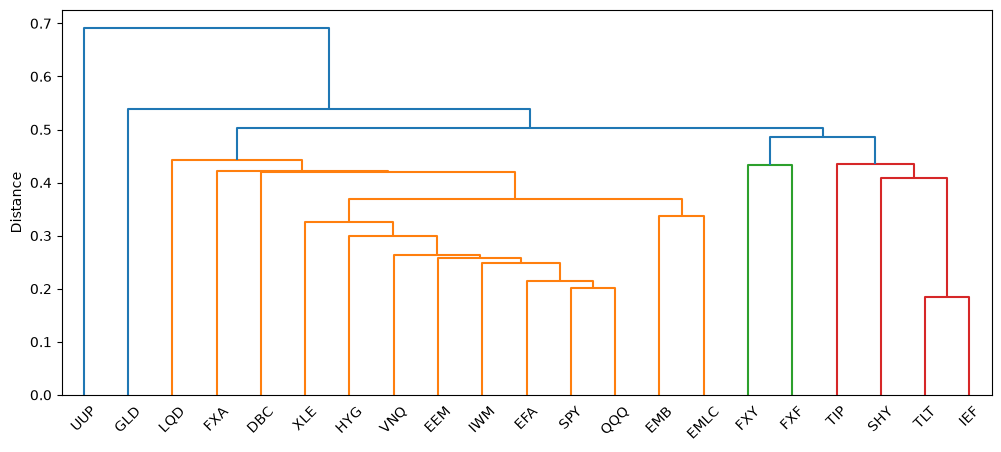

In [26]:
# We then visualize the dendogram

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(link, labels=distance.columns.tolist(), ax=ax)
ax.set_ylabel("Distance")
plt.show()

The results of the tree are partly in line with some of my guesses. They also seem to corss-check the results of the denoising exercise, with three main  signal factors leading to three top-level structures

The tree shows:
- Risk appetite: Orange vs green/red
- Rates: inside the risk off brance, split between green and red
- Dollar/Gold: UUP and Gold unrelated |to the rest

Against my expected groupings:
- Group 1, 2 and 5 are merged
- Group 3 and 4 are also merged
- Gold and Dollar remain ungrouped

The tree is partly in line with my expected groups, and it cross-checks the denoising
result: the three signal factors match the three top-level structures.

- **Risk appetite:** the main split, risk-on (orange) vs risk-off (red and green).
- **Rates:** Treasuries form the tightest group (TLT–IEF at 0.18); the safe-haven
  currencies (FXY, FXF) join them as risk-off assets.
- **Dollar:** UUP joins last (distance ≈ 0.69, i.e. almost uncorrelated with everything).
  Gold is also a loner, joining at ≈ 0.54, but separately from the dollar.

Against my expected groups:
- Groups 1, 2 and 5 merge into one risk-on branch. HYG sits inside the equities, EMB
  and EMLC form a pair, and XLE, DBC, FXA and LQD attach one at a time (no energy group)
- From groups 3 and 4, Treasuries and the yen/franc form one risk-off branch; LQD moved
  to the risk-on branch
- Gold and the dollar stay ungrouped, each on its own.

Caveats: branch colours are a plotting default, not clusters chosen by a method (that
is ONC's job), and the result is for one window (ending 2021-12-31)

Ror diagnostics reason I also want to check how the dendogram looks when the input is denoised; does denoising change the structure of the universe?

In [29]:
# let's create a function to translate correlation to distance as future models will use it

def corr_to_distance(corr):
    float_correction = np.clip((1 - corr) / 2, 0, None) # rounding may cause some tiny negative which won't worrk in a square root
    return np.sqrt(float_correction)

In [34]:
# testing
rng = np.random.default_rng(0)
random_corr = pd.DataFrame(rng.normal(size=(500, 6))).corr() # a random correlation matrix
random_dist = corr_to_distance(random_corr) # its distances

# 1. always true: symmetric, zero diagonal, every value between 0 and 1, no NaNs
assert np.allclose(random_dist, random_dist.T)
assert np.allclose(np.diag(random_dist), 0)
assert ((random_dist >= 0) & (random_dist <= 1)).all().all()
assert random_dist.notna().all().all()

# 2. known answers: ρ = 1 → 0, ρ = 0 → √0.5 ≈ 0.707, ρ = −1 → 1
corr_known = pd.DataFrame([[1, 1, 0],
                           [1, 1, -1],
                           [0, -1, 1]], index=list("ABC"), columns=list("ABC"))
dist_known = corr_to_distance(corr_known)
assert np.isclose(dist_known.loc["A", "B"], 0)
assert np.isclose(dist_known.loc["A", "C"], np.sqrt(0.5))
assert np.isclose(dist_known.loc["B", "C"], 1)

# 3. inputs matter: the most correlated pair is the closest pair
off_diag = ~np.eye(6, dtype=bool) # True everywhere except the diagonal
corr_values = random_corr.where(off_diag) # hide the diagonal (NaN there)
dist_values = random_dist.where(off_diag)
assert corr_values.stack().idxmax() == dist_values.stack().idxmin()

print("corr_to_distance passed all tests")

corr_to_distance passed all tests


In [35]:
# now let's calculate the denoised correlation matrix and calculate distance on it

denoised_corr = denoising.denoise_corr(corr, t=window.shape[0])

denoised_dis = corr_to_distance(denoised_corr)

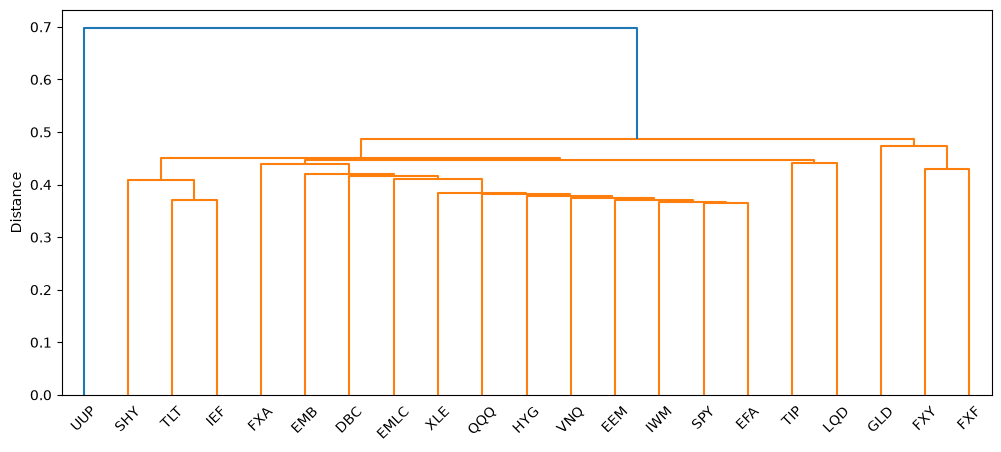

In [37]:
# In order to do so we will use squareform method

link = linkage(squareform(denoised_dis, checks=False), method="single")

# We then visualize the dendogram

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(link, labels=denoised_dis.columns.tolist(), ax=ax)
ax.set_ylabel("Distance")
plt.show()

Denoising alters the composition of the clusters
- all joinings now sit between 0.37 and 0.49 (vs 0.18 and 0.54 before)
- Grouping changes:
    - Gold joins FXFY and FXF as safe heaven (closer to my original 4 groupings)
    - TIP pais with LQD rather than sitting with treasuries
    - Treasuries (SHY, TLT, IEF) and the risk-on core still hang together

Using the raw tree for the HRP process is confirmed by this. This model relies on the fine details that denoising removes
For NCO instead, denoising appears to compress distance so ONC may find fewer broader clusters

## Hierarchical Risk Parity (HRP)

The process to build this allocator is divided in three steps:
1. Define the order in which the ETFs go in, as per the dendrogram
2. Define the risk associated with a group by calculating the group's variance
3. Design the allocator

In [41]:
# order the ETFs

def tree_order(corr):
    dist = corr_to_distance(corr)
    link = linkage(squareform(dist, checks = False), method="single")
    order = leaves_list(link ) # the order of the leaves, left to right
    return list(corr.index[order]) # turn them into tickers

In [67]:
# testing function

# make sure that the order produced by the function reflects that of the dendrogram
# we rebuild the linkages to avoid pollution with the denoised version of the dendrogram
corr = window.corr()
raw_link = linkage(squareform(corr_to_distance(corr), checks=False), method="single")
dn = dendrogram(raw_link, labels=corr.columns.tolist(), no_plot=True)
assert tree_order(corr) == dn["ivl"]

# a block matrix: A and C move together, B and D move together, the two pairs unrelated
corr = pd.DataFrame([[1.0, 0.0, 0.9, 0.0],
                     [0.0, 1.0, 0.0, 0.9],
                     [0.9, 0.0, 1.0, 0.0],
                     [0.0, 0.9, 0.0, 1.0]], index=list("ABCD"), columns=list("ABCD"))
order = tree_order(corr)

# 1. always true: every ticker appears exactly once
assert sorted(order) == sorted(corr.columns)
# 2. known answer: correlated pairs end up next to each other
pos = {t: i for i, t in enumerate(order)}
assert abs(pos["A"] - pos["C"]) == 1
assert abs(pos["B"] - pos["D"]) == 1
# 3. inputs matter: pair A with B instead, and the order follows
corr_swap = corr.loc[list("ACBD"), list("ACBD")].copy()
corr_swap.index = corr_swap.columns = list("ABCD")        # same pattern, relabelled: now A–B and C–D pair up
pos2 = {t: i for i, t in enumerate(tree_order(corr_swap))}
assert abs(pos2["A"] - pos2["B"]) == 1

In [64]:
# calculate cluster variance

def cluster_variance(cov, tickers):
    cluster_covariance = cov.loc[tickers,tickers] # calculate sub covariance of a group
    w = 1/np.diag(cluster_covariance) # inverse-variance weights inside the group
    w = w/w.sum() # normalized
    return w @ cluster_covariance @ w # cluster's variance

In [65]:
# testing function
cov = pd.DataFrame([[1, 0], [0, 4]], index=["A", "B"], columns=["A", "B"])
result = cluster_variance(cov, ["A", "B"])

# 1. always true: a valid covariance matrix
assert result >= 0 # variance can never be negative
assert result <= np.diag(cov).max() # never above the riskiest member's individual variance
# 2. known answer: inverse-variance weights 0.8 / 0.2 → 0.8² × 1 + 0.2² × 4 = 0.8
assert np.isclose(result, 0.8)
# 3. inputs matter: 
assert np.isclose(cluster_variance(cov, ["A"]), 1)        # a group of one: just its own variance
cov_corr = pd.DataFrame([[1, 1], [1, 4]], index=["A", "B"], columns=["A", "B"])   # positive covariance
assert cluster_variance(cov_corr, ["A", "B"]) > result        # moving together → less diversification → more risk

In [78]:
# now we build the allocator

def hrp(window):
    cov = window.cov()
    order = tree_order(window.corr())
    w = pd.Series(1.0, index=order) # every ETF start at weight 1
    groups = [order] # the starting group is the whole ETFs list as per tree order
    while groups:
        new_groups = []
        for g in groups:
            if len(g) == 1:
                continue
            half = len(g) // 2 # // divides and rounds down: 4 → 2, 5 → 2
            left, right = g[:half], g[half:] # first half, second half
            v_left = cluster_variance(cov, left)
            v_right = cluster_variance(cov, right)
            alpha = 1 - v_left / (v_left + v_right) # left half's share
            w.loc[left] *= alpha # scale the left half's weights
            w.loc[right] *= 1 - alpha # and the right half's
            new_groups += [left, right]
        groups = new_groups
    return w.reindex(window.columns)

In [79]:
# testing function

rng = np.random.default_rng(0)
window_two = pd.DataFrame(rng.normal(size=(10000, 2)) * [0.01, 0.02], columns=["A", "B"])
window_many = pd.DataFrame(rng.normal(size=(504, 10)) * np.linspace(0.002, 0.02, 10),
                           columns=list("ABCDEFGHIJ"))
# 1. always true: weights sum to 1, all positive, in the window's column order
w = hrp(window_many)
assert np.isclose(w.sum(), 1)
assert (w > 0).all()
assert list(w.index) == list(window_many.columns)
# 2. known answer: two uncorrelated assets, vols 1% and 2% → one split, α = 1 − 1/(1+4) → 0.8 / 0.2
w = hrp(window_two)
assert np.isclose(w["A"], 0.8, atol=0.02)
assert np.isclose(w["B"], 0.2, atol=0.02)
# 3. inputs matter: tripling A's volatility lowers its weight
window_up = window_many.copy()
window_up["A"] = window_up["A"] * 3
assert hrp(window_up)["A"] < hrp(window_many)["A"]

print("hrp passed all tests")

hrp passed all tests


Let's sanity check the min_var function works as intended on the 31-12-2021 window used before# 

In [82]:
# let's import the data
data = load_data.load_universe()
# let's take the last date of the research period
decision_date = data["rebal_dates"].iloc[-1]
# calculate the lookback window
window = engine.lookback_window(data["returns"], data["eligible"], decision_date, n=LOOKBACK)

# compare hrp with risk weighted and min var allocator
comparison = pd.DataFrame({"risk_weighted": allocators.risk_weighted(window),
                           "min_var": allocators.min_var(window),
                           "hrp": hrp(window)}).round(3)
comparison.sort_values("hrp", ascending=False)

,risk_weighted,min_var,hrp
Ticker,,,
SHY,0.405,0.200,0.908
UUP,0.054,0.200,0.019
IEF,0.063,0.198,0.014
TIP,0.056,0.009,0.013
FXF,0.056,0.181,0.013
FXY,0.051,0.104,0.012
GLD,0.023,0.000,0.004
FXA,0.036,0.021,0.003
LQD,0.031,0.000,0.003


We need to check the variance for SHY before we can draw any conclusion

In [84]:
window.std().sort_values()

Ticker
SHY     0.000613
IEF     0.003968
FXF     0.004424
TIP     0.004428
UUP     0.004601
FXY     0.004877
FXA     0.006910
EMLC    0.007813
HYG     0.007944
LQD     0.008071
EMB     0.009054
GLD     0.010614
TLT     0.011421
DBC     0.013051
EFA     0.015008
SPY     0.015970
EEM     0.017086
QQQ     0.017828
VNQ     0.019819
IWM     0.020516
XLE     0.030003
dtype: float64

Observations:
- The uncapped version of HRP allocates almost entirely to SHY
- I assume that is because of the very variance of SHY
- Bisection in the tree compounds this small number. At every split the half containing SHY looks far less risky than the other one, so the capital keeps accumulating there
- The risk weighted allocator spreads it more, as it compares each ETF to all others once and so it does not compound it
- In practice the 20% cap will do much of the shaping once the allocator goes through the engine

Let's check if we artificially apply the 20% cap now

In [88]:
raw = pd.DataFrame({"risk_weighted": allocators.risk_weighted(window),
                    "min_var": allocators.min_var(window),
                    "hrp": hrp(window)})
raw["risk_weighted_capped"] = engine.apply_cap(raw["risk_weighted"])
raw["hrp_capped"] = engine.apply_cap(raw["hrp"])
raw.round(3).sort_values("hrp", ascending=False)

,risk_weighted,min_var,hrp,risk_weighted_capped,hrp_capped
Ticker,,,,,
SHY,0.405,0.200,0.908,0.200,0.200
UUP,0.054,0.200,0.019,0.073,0.163
IEF,0.063,0.198,0.014,0.084,0.120
TIP,0.056,0.009,0.013,0.075,0.112
FXF,0.056,0.181,0.013,0.076,0.112
FXY,0.051,0.104,0.012,0.069,0.109
GLD,0.023,0.000,0.004,0.031,0.031
FXA,0.036,0.021,0.003,0.048,0.029
LQD,0.031,0.000,0.003,0.041,0.029


Observations:
- All three allocators end up being defensive after capping, with the largest weights in SHY, UUP, IEF, TIP and yen/franc
- HRP with a cap sits between the other two; it's mor concentrated in defensive assets than risk weighted, but more spread than min var
- Risk weighred with a cap is the most even, with each ETF getting around 1-2% (including equities)
- HRP's ranking with a cap still reflects the tree